# Sweeps and reflections: `extrude`, `revolve` and `mirror`

Three operations that build a mesh out of another one (roadmap 3.1.2, 3.1.3 and 3.2.5):

| operation | from | to |
|---|---|---|
| `extrude` | a surface (triangles, quads) or a curve (lines) | a volume (wedges, hexahedra) or a surface (quads), in layers along a vector |
| `revolve` | the same | the same, swept around an axis; cells on the axis collapse |
| `mirror` | any mesh | its reflection across a plane, every cell right side out |

The sweeps follow the parametric primitives' contract: the swept cells only, positive volumes, and the boundary as named `Side` regions (`bottom`, `top` or `start`, `end`, and `side`). `mirror` exists because a reflecting `transform` turns every cell inside out.

In [1]:
import os
import tempfile

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

import meshioplusplus as mp

import subprocess
import sys


def gl_available():
    # Can PyVista render off-screen here? VTK without a GL/EGL/OSMesa library aborts
    # the process instead of raising, so the probe runs in a child process.
    probe = ("import pyvista as pv; pv.OFF_SCREEN = True; "
             "pl = pv.Plotter(off_screen=True, window_size=(64, 64)); "
             "pl.add_mesh(pv.Sphere()); pl.screenshot(return_img=True)")
    try:
        return subprocess.run([sys.executable, '-c', probe], capture_output=True, timeout=120).returncode == 0
    except Exception:
        return False


try:
    import pyvista as pv

    if gl_available():
        # Head-less, static rendering (no display / live server needed).
        pv.OFF_SCREEN = True
        pv.set_jupyter_backend('static')
    else:
        pv = None
        print('No GL available: rendering with matplotlib.')
except ImportError:  # pragma: no cover - pyvista is optional here
    pv = None
    print('PyVista unavailable: rendering with matplotlib.')

DOC_IMAGES = os.path.join(os.path.dirname(os.path.dirname(os.getcwd())), 'doc', 'public', 'images')


def show(img, title=None, figsize=(6, 4.5), save=None):
    """Embed a rendered RGB screenshot (and write it for the docs when `save` is set)."""
    if save:
        try:
            os.makedirs(DOC_IMAGES, exist_ok=True)
            plt.imsave(os.path.join(DOC_IMAGES, save + '.png'), img)
        except Exception as exc:  # pragma: no cover - read-only checkout
            print('doc image not written:', exc)
    plt.figure(figsize=figsize)
    plt.imshow(img)
    plt.axis('off')
    if title:
        plt.title(title)
    plt.tight_layout()
    plt.show()


def to_pyvista(mesh):
    """meshio++ Mesh -> pyvista grid via a temporary .vtu."""
    with tempfile.NamedTemporaryFile(suffix='.vtu', delete=False) as f:
        tmp = f.name
    try:
        mp.write(tmp, mesh)
        return pv.read(tmp)
    finally:
        os.unlink(tmp)


SURFACE_TYPES = {'triangle': 3, 'triangle6': 3, 'quad': 4, 'quad8': 4}


def surface_polygons(mesh):
    """The faces of a mesh as corner-node polygons (curved cells tessellated first)."""
    if any(b.type in ('triangle6', 'quad8', 'tetra10', 'hexahedron20', 'wedge15') for b in mesh.cells):
        mesh = mp.tessellate(mp.Mesh(mesh.points, mesh.cells), levels=3).mesh
    if not any(b.type in SURFACE_TYPES for b in mesh.cells):
        mesh = mp.extract_surface(mesh)
    polys = []
    for block in mesh.cells:
        if block.type in SURFACE_TYPES:
            polys += [mesh.points[row[:SURFACE_TYPES[block.type]]] for row in np.asarray(block.data)]
    return polys


def mpl_draw(ax, polys, color='#2ec4b6', edge='#1f4e79', lw=0.4):
    """matplotlib fallback: flat-shaded polygons in 3-D."""
    ax.add_collection3d(Poly3DCollection(polys, facecolor=color, edgecolor=edge, linewidths=lw, alpha=0.95))
    pts = np.concatenate(polys)
    lo, hi = pts.min(axis=0), pts.max(axis=0)
    centre, half = (lo + hi) / 2, (hi - lo).max() / 2
    ax.set_xlim(centre[0] - half, centre[0] + half)
    ax.set_ylim(centre[1] - half, centre[1] + half)
    ax.set_zlim(centre[2] - half, centre[2] + half)
    ax.set_box_aspect((1, 1, 1))
    ax.set_axis_off()
    ax.view_init(elev=22, azim=-55)


def render(mesh, title, color='#2ec4b6', save=None, figsize=(6, 4.5)):
    """PyVista off-screen render embedded through matplotlib; falls back to matplotlib alone."""
    if pv is not None:
        try:
            pl = pv.Plotter(off_screen=True, window_size=(900, 650))
            surf = to_pyvista(mesh).extract_surface(nonlinear_subdivision=3)
            pl.add_mesh(surf, color=color, show_edges=True, edge_color='#1f4e79', line_width=0.2)
            pl.camera_position = 'iso'
            img = pl.screenshot(return_img=True)
            pl.close()
            show(img, title, figsize=figsize, save=save)
            return
        except Exception as exc:  # head-less GL fallback
            print('PyVista render skipped, drawing with matplotlib:', type(exc).__name__)
    fig = plt.figure(figsize=figsize)
    ax = fig.add_subplot(projection='3d')
    mpl_draw(ax, surface_polygons(mesh), color=color)
    ax.set_title(title)
    plt.show()

No GL available: rendering with matplotlib.


## Extruding a surface

`extrude(mesh, direction, num_layers=..., ratio=...)` copies the points to `num_layers` levels along `direction`, the whole displacement. A `ratio` grades the layers geometrically (each `ratio` times as thick as the one below); `offsets` places them explicitly. Extruding `rectangle` gives `box` **bit for bit**, regions included.

{'num_cells': 108, 'num_hexahedra': 108, 'num_wedges': 0, 'num_pyramids': 0, 'num_tetrahedra': 0, 'num_quads': 0, 'num_triangles': 0, 'num_flipped': 0, 'min_scaled_jacobian': 1.0, 'warnings': []}
regions: {'bottom': 18, 'side': 108, 'top': 18, 'xmax': 18, 'xmin': 18, 'ymax': 36, 'ymin': 36}
levels z: [0.     0.0613 0.147  0.2671 0.4352 0.6705 1.    ]


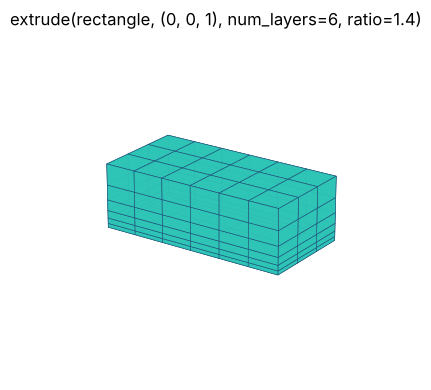

extrude(rectangle) == box: True


In [2]:
rect = mp.rectangle(dims=(6, 3), size=(3.0, 1.5))
slab, report = mp.extrude(rect, (0.0, 0.0, 1.0), num_layers=6, ratio=1.4, record_layers=True, return_report=True)
print(report)
print('regions:', {r.name: len(r.entries) for r in slab.regions})
print('levels z:', np.round(np.unique(slab.points[:, 2]), 4))
render(slab, 'extrude(rectangle, (0, 0, 1), num_layers=6, ratio=1.4)')

same = mp.extrude(mp.rectangle(dims=(3, 2)), num_layers=4)
box = mp.box(dims=(3, 2, 4))
print('extrude(rectangle) == box:', np.array_equal(same.points, box.points) and np.array_equal(same.cells[0].data, box.cells[0].data))

Triangles sweep to wedges, and a face whose normal points against the direction is turned first, so no cell is ever inverted (`num_flipped` counts them). A curve's lines sweep to quads: here a closed circle becomes a tube wall.

wedges: 162 | turned: 54 | inverted: 0


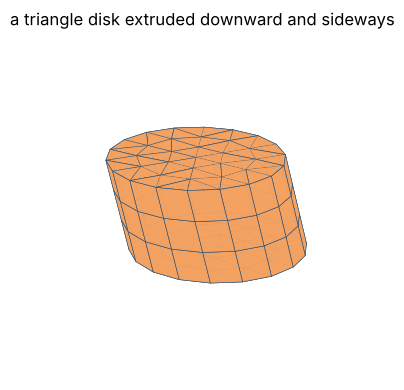

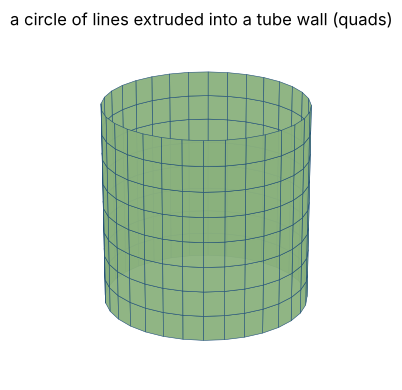

In [3]:
disk = mp.disk(radius=1.0, n=3, cell_type='triangle')
prism, rp = mp.extrude(disk, (0.3, 0.0, -1.0), num_layers=3, return_report=True)
print('wedges:', rp['num_wedges'], '| turned:', rp['num_flipped'], '| inverted:', mp.check_quality(prism)['num_inverted'])
render(prism, 'a triangle disk extruded downward and sideways', color='#f4a261')

t = np.linspace(0.0, 2 * np.pi, 33)[:-1]
circle = mp.Mesh(np.column_stack([np.cos(t), np.sin(t), np.zeros_like(t)]), [('line', np.array([[i, (i + 1) % 32] for i in range(32)]))])
wall = mp.extrude(circle, (0.0, 0.0, 2.0), num_layers=8)
render(wall, 'a circle of lines extruded into a tube wall (quads)', color='#8ab17d')

## Revolving

`revolve(mesh, axis, axis_point=..., angle=..., num_layers=...)` turns the profile about an axis, `angle` degrees in `num_layers` steps. The default axis is `y`, so an `(r, z)` profile drawn in the xy plane becomes the solid it describes. Points on the axis stay put: the quads touching it become **wedges**, a triangle with a corner on it **pyramids**. A full turn closes on itself and has no `start` or `end`.

{'num_cells': 576, 'num_hexahedra': 432, 'num_wedges': 144, 'num_pyramids': 0, 'num_tetrahedra': 0, 'num_quads': 0, 'num_triangles': 0, 'num_flipped': 24, 'num_on_axis': 7, 'min_scaled_jacobian': 0.2588190451025204, 'full': True, 'warnings': []}
regions: {'side': 336, 'xmax': 144, 'xmin': 0, 'ymax': 96, 'ymin': 96}
conforming: True | boundary facets: 336


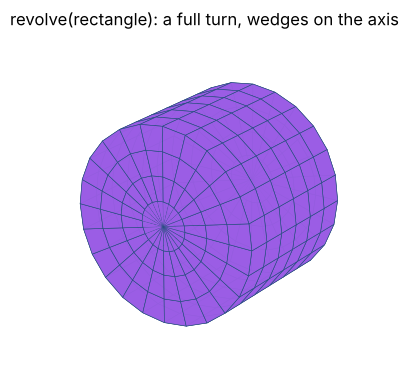

sector regions: {'end': 12, 'side': 84, 'start': 12, 'xmax': 24, 'xmin': 24, 'ymax': 18, 'ymin': 18}


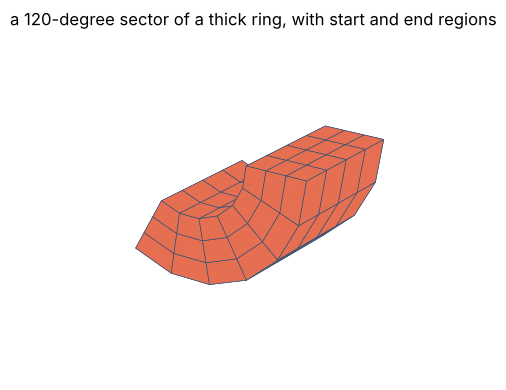

In [4]:
R, H, L = 1.0, 1.5, 24
profile = mp.rectangle(dims=(4, 6), size=(R, H))
solid, rr = mp.revolve(profile, num_layers=L, return_report=True)
print(rr)
print('regions:', {r.name: len(r.entries) for r in solid.regions})
_, conf = mp.check_conformity(solid, return_report=True)
print('conforming:', conf['conforming'], '| boundary facets:', conf['num_boundary_facets'])
render(solid, 'revolve(rectangle): a full turn, wedges on the axis', color='#9b5de5')

sector, rs = mp.revolve(mp.rectangle(dims=(3, 4), size=(0.5, 1.0), origin=(0.5, 0.0, 0.0)), angle=120.0, num_layers=6, return_report=True)
print('sector regions:', {r.name: len(r.entries) for r in sector.regions})
render(sector, 'a 120-degree sector of a thick ring, with start and end regions', color='#e76f51')

A curve revolves into a surface. A semicircle of lines from pole to pole gives a sphere: the two lines touching the axis become rings of triangles, the rest quads.

{'num_quads': 240, 'num_triangles': 48, 'num_on_axis': 2, 'full': True}


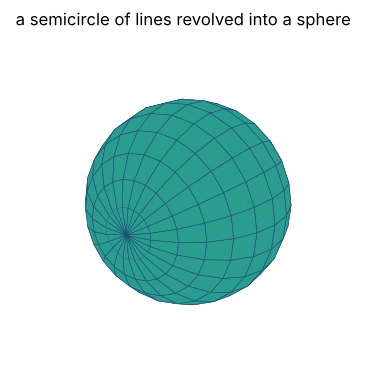

In [5]:
N = 12
phi = np.pi * np.arange(N, -1, -1) / N
arc_pts = np.column_stack([np.sin(phi), -np.cos(phi), np.zeros_like(phi)])
arc_pts[[0, -1], 0] = 0.0
arc = mp.Mesh(arc_pts, [('line', np.array([[i, i + 1] for i in range(N)]))])
sphere, rsph = mp.revolve(arc, num_layers=24, return_report=True)
print({k: rsph[k] for k in ('num_quads', 'num_triangles', 'num_on_axis', 'full')})
render(sphere, 'a semicircle of lines revolved into a sphere', color='#2a9d8f')

## Mirroring

A reflecting `transform` moves the points and keeps the connectivity, so every cell comes out inverted. `mirror` permutes each cell's nodes as well (keeping mid-edge nodes in their slots) and moves `Side` region entries to their facets' new numbers. With `keep_original=True` the result is the input followed by its image, the points on the plane shared: a half model becomes a whole, conforming one.

transform: inverted 72 of 72
mirror:    inverted 0
{'num_flipped_cells': 72, 'num_points_on_plane': 25, 'num_dropped_cells': 0, 'num_dropped_sides': 8, 'warnings': ["region 'xmin': 8 facet(s) on the mirror plane are interior and were dropped"]}
whole model conforming: True | points 175 -> 325


meshio warning [transform.cpp:206] transform: orientation-reversing (negative determinant): every cell comes out inverted; mirror reflects with the cells right side out


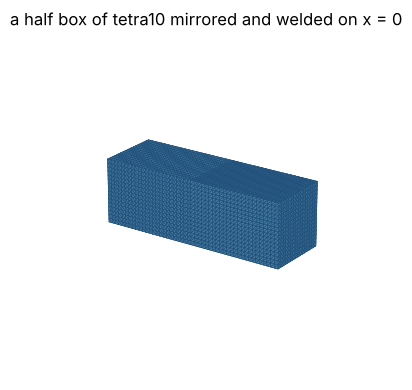

In [6]:
half = mp.box(dims=(3, 2, 2), size=(1.5, 1.0, 1.0), cell_type='tetra', order=2)
flipped = mp.transform(half, matrix=np.diag([-1.0, 1.0, 1.0, 1.0]))
print('transform: inverted', mp.check_quality(flipped)['num_inverted'], 'of', sum(len(b.data) for b in half.cells))
print('mirror:    inverted', mp.check_quality(mp.mirror(half))['num_inverted'])

whole, rm = mp.mirror(half, keep_original=True, return_report=True)
print(rm)
_, conf = mp.check_conformity(whole, return_report=True)
print('whole model conforming:', conf['conforming'], '| points', len(half.points), '->', len(whole.points))
render(whole, 'a half box of tetra10 mirrored and welded on x = 0', color='#457b9d')

## On the command line and in a pipeline

All three are CLI verbs in both CLIs (`extrude`, `revolve`, `mirror`), MCP tools, and pipeline steps (`Extrude`, `Revolve`, `Mirror`); here a pipeline builds a rectangle, sweeps it into a quarter of a cylinder, and mirrors the quarter into a half.

{'op': 'Generate', 'NumPoints': 25.0, 'NumCells': 16.0}
{'op': 'Revolve', 'NumCells': 96.0, 'NumOnAxis': 5.0, 'MinScaledJacobian': 0.2588190451025207}
{'op': 'Mirror', 'NumFlippedCells': 96.0, 'NumPointsOnPlane': 25.0, 'NumDroppedCells': 0.0}
inverted: 0


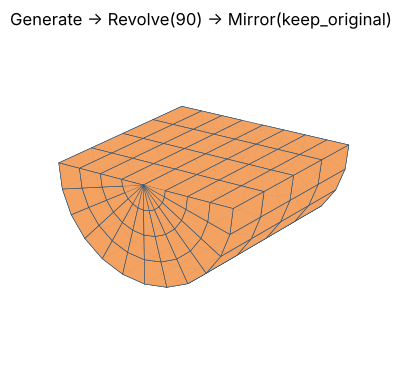

In [7]:
with tempfile.TemporaryDirectory() as d:
    out = os.path.join(d, 'half_cylinder.vtu')
    report = mp.run_pipeline({
        'Version': 1,
        'Operations': [
            {'Op': 'Generate', 'Shape': 'rectangle', 'Dims': [4, 4], 'Size': [1.0, 2.0]},
            {'Op': 'Revolve', 'Angle': 90, 'NumLayers': 6},
            {'Op': 'Mirror', 'Normal': [1, 0, 0], 'KeepOriginal': True},
        ],
        'Output': {'Path': out},
    })
    for step in report['steps']:
        print(step)
    half_cylinder = mp.read(out)
print('inverted:', mp.check_quality(half_cylinder)['num_inverted'])
render(half_cylinder, 'Generate -> Revolve(90) -> Mirror(keep_original)', color='#f4a261')